# Inspect amplifier.dat

Steps through the spike detection of `intan_binning` on a window of an Intan RHX recording,
with the settings of the online config (`spikes` section), using the same code as online:

1. **bandpass**: causal Butterworth `band_hz`
2. **common reference**: median (or mean) of the channels with `inner < d <= outer` (`local_radius`,
   positions from `positions_file`), or of all channels
3. **matched filter**: correlation with the waveform in `template_file`
4. **threshold**: crossings above `threshold` x the noise SD of the matched filter output

As online, the noise SD is estimated over the first `noise_s` seconds of the recording, so the
spikes shown are the ones `wasabi_online` would count. Set `RECORDING_DIR`, or leave it `None`
for `paths.wasabi_data_dir` of the config.

In [36]:
RECORDING_DIR = '/home/bryan/mnt/cullen_data/Current Project Databases - NHP/2025 Cerebellum prosthesis/WASABI_test_data/test_data_261110_104049'  # e.g. "/path/to/WASABI_test_data_261110_094754"
T_START = 10.0        # s from the start of the file
T_LEN = 0.5           # s of data to look at
FOCUS = 40            # channel (column of amplifier.dat) to center the plots on
NUM_SHOWN = 3         # channels shown: the sites nearest FOCUS, by depth

In [37]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from scipy import signal

ROOT = Path.cwd().parent if Path.cwd().name == "scripts" else Path.cwd()
sys.path.insert(0, str(ROOT / "experiment" / "src"))
from config_loading import load_config
from intan_binning import AMPLIFIER_UV_PER_BIT, _enabled_channels, load_positions, local_neighbors, make_detector

cfg = load_config()
recording_dir = Path(RECORDING_DIR) if RECORDING_DIR else cfg.data_path(cfg.paths.wasabi_data_dir)
fs = cfg.recording.sample_rate
stream_only = ("sample_rate", "ir_channel", "edge", "trial_ms", "offset_ms", "bin_ms", "analog_threshold")
detection = {k: v for k, v in cfg.intan_stream_kwargs().items() if k not in stream_only}
sp = cfg.spikes
print(f"bandpass   {sp.band_hz[0]:g}-{sp.band_hz[1]:g} Hz, order {sp.filter_order}")
print(f"reference  {sp.reference}, " + (f"local {sp.local_radius[0]:g} < d <= {sp.local_radius[1]:g} um ({Path(sp.positions_file).name})" if sp.local_radius else "global"))
print(f"template   {Path(sp.template_file).name if sp.template_file else 'none (threshold the signal)'}")
print(f"threshold  {sp.threshold:g} x noise SD, noise over the first {sp.noise_s:g} s, refractory {sp.refractory_ms:g} ms")

bandpass   300-10000 Hz, order 3
reference  median, local 30 < d <= 150 um (ImecPrimateStimRec128.mat)
template   median_extremum_templates_norm_NPRW.npy
threshold  4 x noise SD, noise over the first 10 s, refractory 1 ms


## The recording

In [38]:
names = _enabled_channels(recording_dir)
all_names = _enabled_channels(recording_dir, enabled_only=False)  # disabled ones too: columns of the probe map
detection["all_channels"] = all_names
N = len(names)
path = recording_dir / "amplifier.dat"
num_samples = path.stat().st_size // (2 * N)
amp = np.memmap(path, dtype="<i2", mode="r", shape=(num_samples, N))
print(f"{path}\n{N} of {len(all_names)} channels enabled ({names[0]} .. {names[-1]}), {num_samples} samples = {num_samples / fs:.1f} s at {fs:g} Hz")
if path.stat().st_size % (2 * N):
    print(f"warning: {path.stat().st_size % (2 * N)} trailing bytes (file still being written, or wrong channel count)")
time_path = recording_dir / "time.dat"
if time_path.exists():
    t = np.memmap(time_path, dtype="<i4", mode="r")
    print(f"time.dat: first timestamp {t[0]}, {np.count_nonzero(np.diff(t[:num_samples]) != 1)} gaps")
saturated = np.flatnonzero(np.any(np.abs(amp[: min(num_samples, int(10 * fs))]) >= 32767, axis=0))
print("saturated in the first 10 s:", saturated.tolist())

/home/bryan/mnt/cullen_data/Current Project Databases - NHP/2025 Cerebellum prosthesis/WASABI_test_data/test_data_261110_104049/amplifier.dat
64 of 64 channels enabled (A-000 .. B-031), 1504000 samples = 50.1 s at 30000 Hz
time.dat: first timestamp 0, 0 gaps
saturated in the first 10 s: []


## Probe and local reference

Site positions, and for `FOCUS` the channels its reference is taken from (the annulus
`inner < d <= outer`). The shown channels are the `NUM_SHOWN` sites nearest `FOCUS`.

64 of 64 channels on the probe map
neighbors per channel: min 13, median 25, max 27


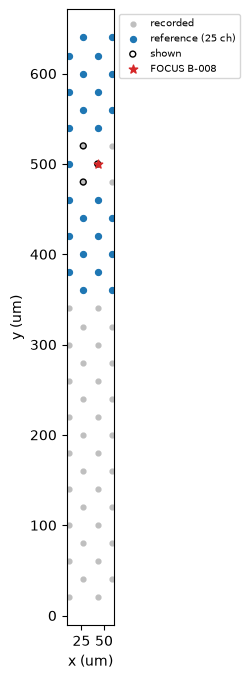

In [39]:
positions = load_positions(detection["positions_file"], names, all_names) if detection["positions_file"] else None
if positions is not None:
    placed = np.flatnonzero(~np.isnan(positions[:, 0]))
    print(f"{len(placed)} of {N} channels on the probe map")
    if np.isnan(positions[FOCUS, 0]):
        raise ValueError(f"FOCUS {names[FOCUS]} has no position; pick one of {placed[:10].tolist()} ...")
    shown = [int(i) for i in np.argsort(np.linalg.norm(positions - positions[FOCUS], axis=1))[:NUM_SHOWN]]
    shown.sort(key=lambda i: -positions[i, 1])  # top of the probe first
    fig, ax = plt.subplots(figsize=(3, 8))
    ax.scatter(*positions.T, s=12, color="0.75", label="recorded")
    if detection["local_radius"]:
        ring = local_neighbors(positions, detection["local_radius"])[FOCUS]
        ax.scatter(*positions[ring].T, s=18, color="tab:blue", label=f"reference ({len(ring)} ch)")
        counts = [len(nb) for nb in local_neighbors(positions, detection["local_radius"])]
        print(f"neighbors per channel: min {min(counts)}, median {int(np.median(counts))}, max {max(counts)}")
    ax.scatter(*positions[shown].T, s=18, facecolor="none", edgecolor="k", label="shown")
    ax.scatter(*positions[FOCUS], s=40, marker="*", color="tab:red", label=f"FOCUS {names[FOCUS]}")
    ax.set_aspect("equal")
    ax.set_xlabel("x (um)"); ax.set_ylabel("y (um)")
    ax.legend(fontsize=7, loc="upper left", bbox_to_anchor=(1, 1))
else:
    shown = list(range(FOCUS, min(FOCUS + NUM_SHOWN, N)))
    print("no positions_file: showing consecutive channels")

## Run the pipeline

Thresholds come from the first `noise_s` seconds of the file, as online. The window is
processed with 0.5 s before it, so the filter has settled, and 10 ms after it, so the matched
filter can score spikes at its end; each stage is kept for plotting.

In [40]:
noise_detector = make_detector(names, fs, **detection)
noise_end = min(int(detection["noise_s"] * fs), num_samples)
for a in range(0, noise_end, int(fs)):  # in 1 s chunks, as the stream does
    noise_detector.process(np.array(amp[a : min(a + int(fs), noise_end)]), final=a + int(fs) >= noise_end)
thresholds = noise_detector.thresholds
noise_sd = thresholds / detection["threshold"]

pad = min(int(0.5 * fs), int(T_START * fs))
i0, i1 = int(T_START * fs) - pad, min(int((T_START + T_LEN) * fs), num_samples)
raw = np.array(amp[i0 : min(i1 + int(0.01 * fs), num_samples)])
window = slice(pad, i1 - i0)

# Each stage, with the detector's own methods
stages = make_detector(names, fs, **detection)
bandpassed = make_detector(names, fs, **{**detection, "reference": "none"}).filter(raw)
reference = stages.common_reference(bandpassed) if detection["reference"] != "none" else np.zeros_like(bandpassed)
referenced = bandpassed - reference
matched = stages.match(referenced)

# Spikes as online: same pipeline, thresholds from the start of the recording
detector = make_detector(names, fs, **detection)
detector.thresholds = thresholds
samples, chans = detector.process(raw)
keep = (samples >= window.start) & (samples < window.stop)
samples, chans = samples[keep] - pad, chans[keep]

raw_uv = raw[window].astype(np.float32) * AMPLIFIER_UV_PER_BIT
bandpassed, reference, referenced = (s[window] for s in (bandpassed, reference, referenced))
matched_ahead = matched[pad:]  # with the 10 ms after the window: y[n] scores the spike `lag` samples back
matched = matched_ahead[: len(raw_uv)]
time_s = (i0 + pad + np.arange(len(raw_uv))) / fs
rate = np.bincount(chans, minlength=N) / (len(time_s) / fs)
print(f"{len(samples)} spikes in {len(time_s) / fs:g} s, {rate.mean():.1f} per channel per s")

386 spikes in 0.5 s, 12.1 per channel per s


## Stages

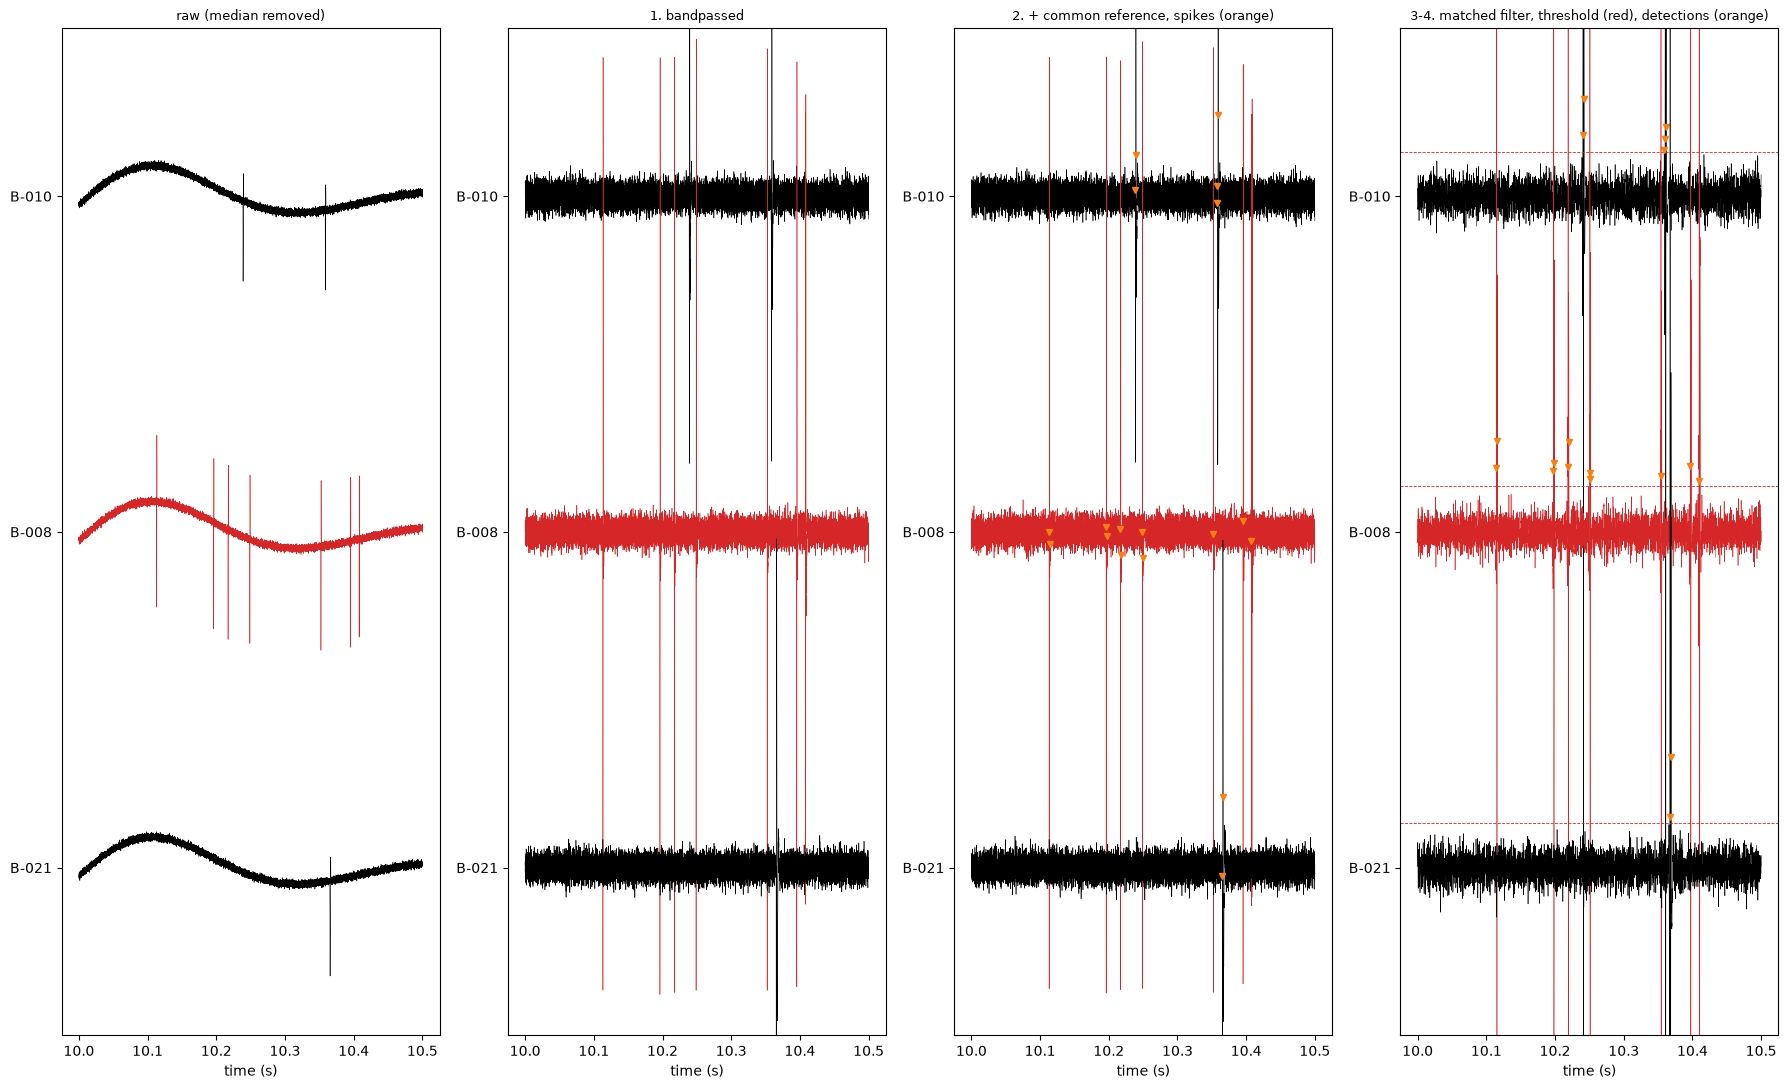

In [41]:
def stacked(ax, data, step, title, *, spikes=False, threshold=False, shift=0, gap=6, scale=2):
    """Plot the `shown` channels of `data` stacked top to bottom, `gap * step` apart.

    `shift`: samples from a spike's trough to where it shows in `data` (the lag, for y).
    `scale`: amplitude gain on the traces (and threshold lines), without changing the spacing.
    """
    offsets = -gap * step * np.arange(len(shown))
    data = scale * data
    for offset, ch in zip(offsets, shown):
        ax.plot(time_s, data[:, ch] + offset, lw=0.4, color="tab:red" if ch == FOCUS else "k")
        if threshold:
            ax.axhline(scale * thresholds[ch] + offset, color="tab:red", lw=0.6, ls="--")
        if spikes:
            s = samples[chans == ch] + shift
            s = s[s < len(data)]
            ax.plot(time_s[s], data[s, ch] + offset, "v", color="tab:orange", ms=4)
    ax.set_yticks(offsets, [names[ch] for ch in shown])
    ax.set_ylim(offsets[-1] - gap * step / 2, gap * step / 2)  # same row layout in every panel
    ax.set_title(title, fontsize=9)
    ax.set_xlabel("time (s)")


def spread(x):
    """Trace spacing unit: 7x the median per-channel std over `shown`."""
    return 7 * np.median(np.std(x[:, shown], axis=0))


fig, axes = plt.subplots(1, 4, figsize=(18, 3 * len(shown) + 2), sharex=True)
stacked(axes[0], raw_uv - np.median(raw_uv, axis=0), spread(raw_uv), "raw (median removed)")
stacked(axes[1], bandpassed, spread(bandpassed), "1. bandpassed")
stacked(axes[2], referenced, spread(referenced), "2. + common reference, spikes (orange)", spikes=True)
stacked(
    axes[3], matched, 2.5 * np.median(thresholds[shown]),
    "3-4. matched filter, threshold (red), detections (orange)",
    threshold=True, spikes=True,
    shift=detector.lag,  # each at its threshold crossing, `lag` after the trough
)
plt.tight_layout()

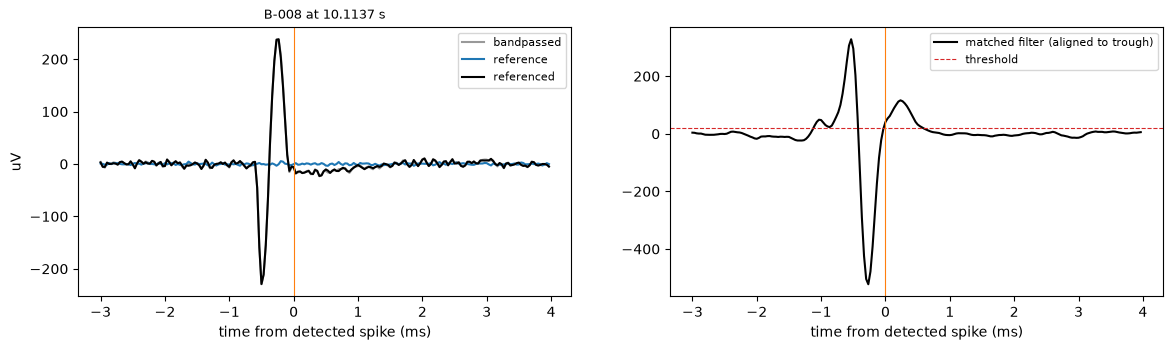

In [42]:
# One spike of FOCUS up close: every stage, and the reference that was subtracted
s = samples[chans == FOCUS]
if len(s):
    center = s[np.argmax(matched_ahead[s + detector.lag, FOCUS])]  # its strongest
    w = slice(max(center - int(0.003 * fs), 0), min(center + int(0.004 * fs), len(time_s)))
    t_ms = (np.arange(w.start, w.stop) - center) / fs * 1e3
    fig, axes = plt.subplots(1, 2, figsize=(14, 3.5))
    axes[0].plot(t_ms, bandpassed[w, FOCUS], color="0.6", label="bandpassed")
    axes[0].plot(t_ms, reference[w, FOCUS] if reference.shape[1] > 1 else reference[w, 0], color="tab:blue", label="reference")
    axes[0].plot(t_ms, referenced[w, FOCUS], color="k", label="referenced")
    axes[0].set_ylabel("uV")
    axes[0].set_title(f"{names[FOCUS]} at {time_s[center]:.4f} s", fontsize=9)
    # y[n] scores the template ending at n, so shift it back by the lag to line up with the trough
    shift = slice(w.start + detector.lag, w.stop + detector.lag)
    y = matched_ahead[shift, FOCUS]
    axes[1].plot(t_ms[: len(y)], y, color="k", label="matched filter (aligned to trough)")
    axes[1].axhline(thresholds[FOCUS], color="tab:red", ls="--", lw=0.8, label="threshold")
    for ax in axes:
        ax.axvline(0, color="tab:orange", lw=0.8)
        ax.set_xlabel("time from detected spike (ms)")
        ax.legend(fontsize=8)
else:
    print(f"no spikes on {names[FOCUS]} in this window")

## Template vs detected spikes

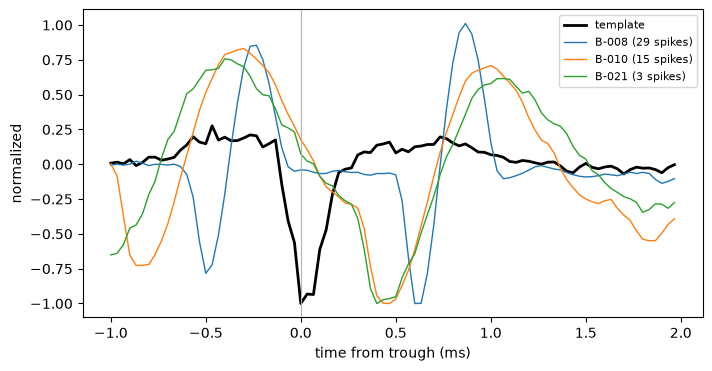

In [34]:
# Mean referenced waveform at the detected spikes of the most active shown channels, against
# the template (both scaled to unit trough). They should line up if the template fits.
w = detector.template
trough = int(np.argmin(w))
lags = np.arange(len(w)) - trough
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(lags / fs * 1e3, w / -w.min(), color="k", lw=2, label="template")
for ch in sorted(shown, key=lambda c: -np.sum(chans == c))[:4]:
    s = samples[chans == ch]
    s = s[(s >= trough) & (s < len(referenced) - len(w) + trough)]
    if len(s):
        mean = referenced[s[:, None] + lags[None], ch].mean(axis=0)
        ax.plot(lags / fs * 1e3, mean / -mean.min(), lw=1, label=f"{names[ch]} ({len(s)} spikes)")
ax.axvline(0, color="0.7", lw=0.8)
ax.set_xlabel("time from trough (ms)")
ax.set_ylabel("normalized")
ax.legend(fontsize=8)

## Noise and spike rate across the probe

The reference should lower the noise; the noise SD of the matched filter output is what the
thresholds are scaled from. `noise_s` estimate (used online) vs this window: a large
difference means the noise changed since the start of the recording.

0 channels with the noise >20% off the online estimate: []
quietest (dead or shorted?): ['A-014', 'B-025', 'A-000', 'B-026', 'B-012']


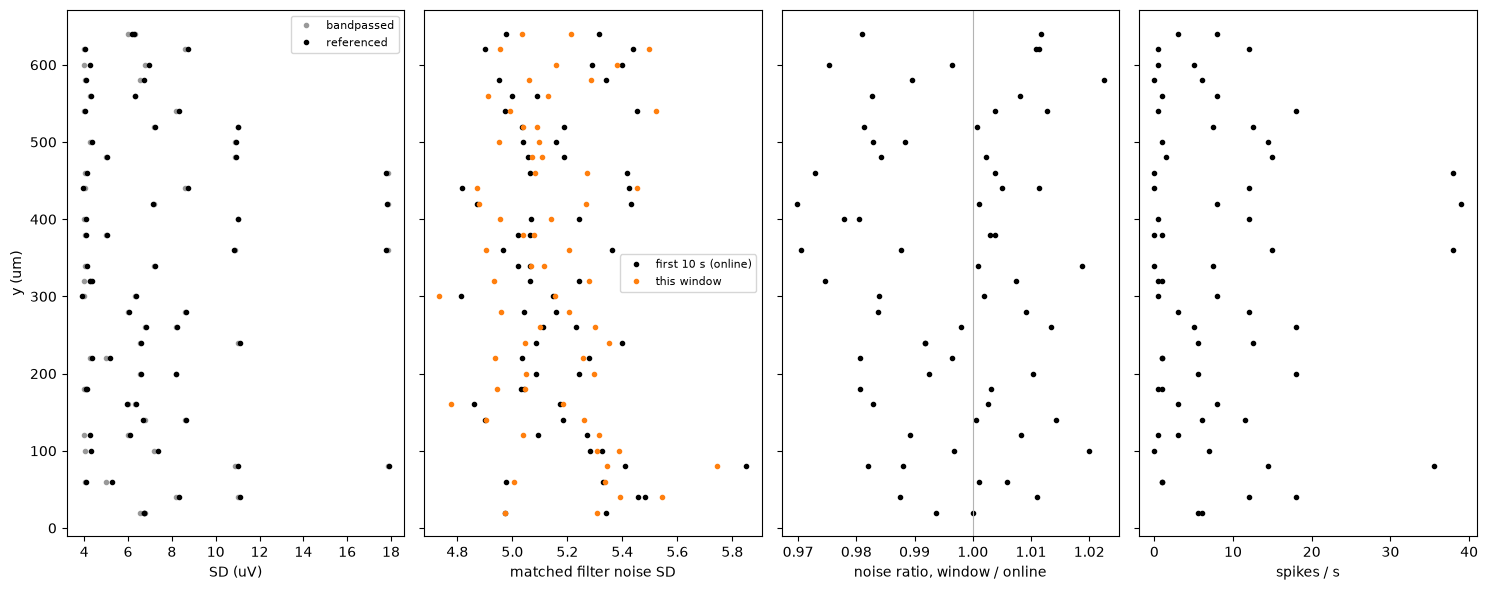

In [35]:
window_noise = np.median(np.abs(matched), axis=0) / 0.6745
order = np.argsort(positions[:, 1]) if positions is not None else np.arange(N)
depth = positions[order, 1] if positions is not None else order
fig, axes = plt.subplots(1, 4, figsize=(15, 6), sharey=True)
axes[0].plot(np.std(bandpassed, axis=0)[order], depth, ".", color="0.6", label="bandpassed")
axes[0].plot(np.std(referenced, axis=0)[order], depth, ".", color="k", label="referenced")
axes[0].set_xlabel("SD (uV)"); axes[0].legend(fontsize=8)
axes[1].plot(noise_sd[order], depth, ".", color="k", label=f"first {detection['noise_s']:g} s (online)")
axes[1].plot(window_noise[order], depth, ".", color="tab:orange", label="this window")
axes[1].set_xlabel("matched filter noise SD"); axes[1].legend(fontsize=8)
axes[2].plot((window_noise / noise_sd)[order], depth, ".", color="k")
axes[2].axvline(1, color="0.7", lw=0.8)
axes[2].set_xlabel("noise ratio, window / online")
axes[3].plot(rate[order], depth, ".", color="k")
axes[3].set_xlabel("spikes / s")
axes[0].set_ylabel("y (um)" if positions is not None else "channel")
plt.tight_layout()
drift = np.abs(window_noise / noise_sd - 1) > 0.2
print(f"{drift.sum()} channels with the noise >20% off the online estimate: {[names[i] for i in np.flatnonzero(drift)][:10]}")
print("quietest (dead or shorted?):", [names[i] for i in np.argsort(noise_sd)[:5]])